# Multimodal AI for medical imaging: hands-on notebook

Companion to the FDP session *Multimodal AI Models for Medical Imaging Analysis*. Three workflows on real, public, de-identified data:

| | Workflow | Data | Model |
|---|---|---|---|
| A | Load and view a DICOM CT study | LIDC-IDRI-0001 (TCIA, CC BY 3.0) | none |
| B | Match an X-ray with descriptions | the same patient's chest X-ray (DICOM), plus Indiana University X-rays (PNG) | BiomedCLIP |
| C | Outline anatomy and a nodule | the same CT | TotalSegmentator, MedSAM |

**Before you start:** run `python download_data.py` once (about 90 MB for workflows A–C; the optional IU X-ray set is 1.4 GB). See `README.md` for setup, runtimes and troubleshooting.

**Privacy.** These datasets were de-identified by their publishers. Hospital DICOM files are not: never upload real patient files to online notebooks or AI services.

**Interpretation.** Every score in this notebook is a research output, not a diagnosis.

In [1]:
# Setup: libraries and paths. Runs on a GPU if one is available, otherwise on the CPU.
import glob, json, os, time
import numpy as np
import matplotlib.pyplot as plt
import pydicom
import SimpleITK as sitk
import torch

DATA = 'data/raw'
LIDC = os.path.join(DATA, 'lidc')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Running on', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU')

Running on NVIDIA RTX PRO 4000 Blackwell


## Workflow A — DICOM loading and visualisation

### A1. A folder of files is not yet a scan
A CT series arrives as one file per slice. File names say nothing about where a slice sits in the body.

In [2]:
# A1. Read every file's header (not the pixels yet) and look at its position
ct_dir = glob.glob(os.path.join(LIDC, 'CT-*'))[0]
files = sorted(glob.glob(os.path.join(ct_dir, '*.dcm')))
headers = [pydicom.dcmread(f, stop_before_pixels=True) for f in files]

for f, h in list(zip(files, headers))[:4]:
    print(os.path.basename(f), '| instance', h.InstanceNumber,
          '| z =', float(h.ImagePositionPatient[2]), 'mm')

# Sort by height in the body (z), not by file name
order = np.argsort([float(h.ImagePositionPatient[2]) for h in headers])
headers = [headers[i] for i in order]
files = [files[i] for i in order]
print(len(files), 'slices, from z =', float(headers[0].ImagePositionPatient[2]),
      'to', float(headers[-1].ImagePositionPatient[2]), 'mm')

00000001.dcm | instance 80 | z = -207.5 mm
00000002.dcm | instance 52 | z = -137.5 mm
00000003.dcm | instance 42 | z = -112.5 mm
00000004.dcm | instance 59 | z = -155.0 mm
133 slices, from z = -340.0 to -10.0 mm


In [3]:
# A1b. A few tags that matter for analysis (and one group that matters for privacy)
h = headers[0]
for kw in ['Modality', 'Manufacturer', 'SliceThickness', 'PixelSpacing',
           'RescaleSlope', 'RescaleIntercept', 'PatientName', 'PatientIdentityRemoved']:
    print(f'{kw:24s}', h.get(kw, '(not present)'))

Modality                 CT
Manufacturer             GE MEDICAL SYSTEMS
SliceThickness           2.500000
PixelSpacing             [0.703125, 0.703125]
RescaleSlope             1
RescaleIntercept         -1024
PatientName              
PatientIdentityRemoved   YES


### A2. Stored numbers → Hounsfield units → a picture
Each file stores integers. `RescaleSlope` and `RescaleIntercept` turn them into Hounsfield units (HU). A *window* then chooses which HU become black to white.

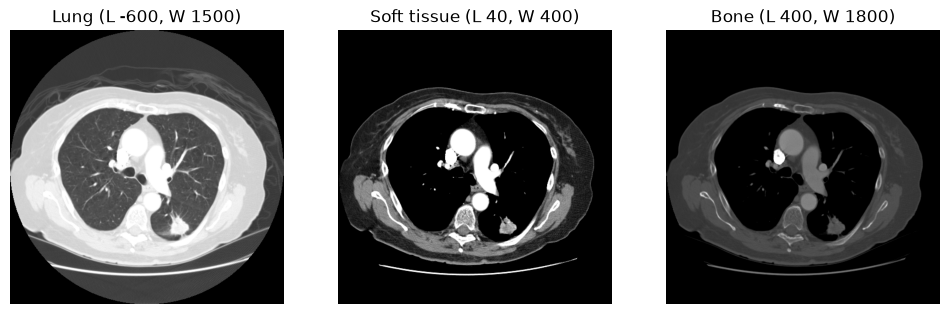

HU range on this slice: -2048 to 3071


In [4]:
# A2. Build the volume in Hounsfield units, then show one slice with three windows
volume = np.stack([pydicom.dcmread(f).pixel_array for f in files]).astype(np.float32)
volume = volume * float(h.RescaleSlope) + float(h.RescaleIntercept)   # stored → HU

def window(img, level, width):
    lo = level - width / 2
    return np.clip((img - lo) / width, 0, 1)

k = 89                                         # the slice through the nodule
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, L, W) in zip(axes, [('Lung', -600, 1500), ('Soft tissue', 40, 400), ('Bone', 400, 1800)]):
    ax.imshow(window(volume[k], L, W), cmap='gray'); ax.set_title(f'{name} (L {L}, W {W})'); ax.axis('off')
plt.show()
print('HU range on this slice:', int(volume[k].min()), 'to', int(volume[k].max()))

### A3. Three planes from one volume
SimpleITK reads a series, sorts it and keeps the spacing, so views in other planes have the right proportions.

Size (512, 512, 133) | spacing (mm) (0.7, 0.7, 2.5)


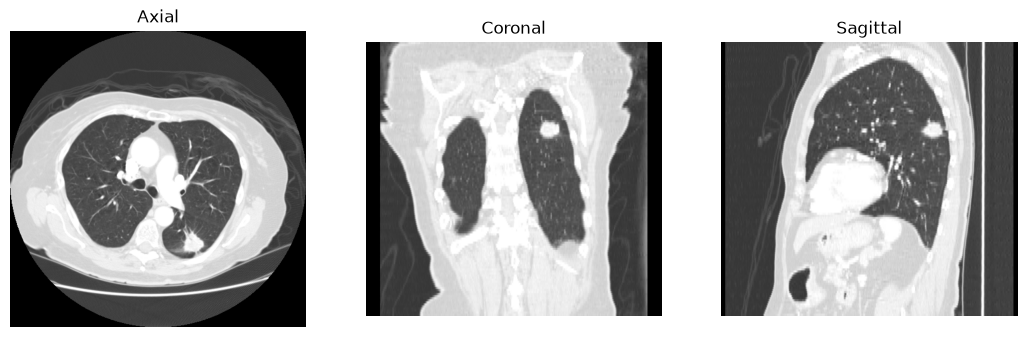

In [5]:
# A3. Let SimpleITK read and sort the series, then cut it three ways
reader = sitk.ImageSeriesReader()
reader.SetFileNames(reader.GetGDCMSeriesFileNames(ct_dir))
ct = reader.Execute()                          # already in HU, with spacing and position
arr = sitk.GetArrayFromImage(ct)               # (z, y, x)
sx, sy, sz = ct.GetSpacing()
print('Size', ct.GetSize(), '| spacing (mm)', tuple(round(s, 2) for s in ct.GetSpacing()))

z, y, x = 89, 367, 316                         # the nodule
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(window(arr[z], -600, 1500), cmap='gray'); axes[0].set_title('Axial')
axes[1].imshow(window(arr[::-1, y, :], -600, 1500), cmap='gray', aspect=sz / sx); axes[1].set_title('Coronal')
axes[2].imshow(window(arr[::-1, :, x], -600, 1500), cmap='gray', aspect=sz / sy); axes[2].set_title('Sagittal')
for ax in axes: ax.axis('off')
plt.show()

In [6]:
# A4. Other modalities, other rules: the same patient's X-ray, and a brain MRI series
dx = pydicom.dcmread(glob.glob(os.path.join(LIDC, 'DX-*', '*.dcm'))[0])
print('X-ray:', dx.Rows, 'x', dx.Columns, '|', dx.BitsStored, 'bits |', dx.PhotometricInterpretation,
      '| window tags', dx.WindowCenter, dx.WindowWidth, '(these look copied from a CT)')
mri_dir = os.path.join(DATA, 'upenn', 't2_Flair_axial')
if os.path.isdir(mri_dir):
    m = pydicom.dcmread(sorted(glob.glob(os.path.join(mri_dir, '*.dcm')))[0], stop_before_pixels=True)
    print('MRI:', m.SeriesDescription, '| slice', m.SliceThickness, 'mm | no Hounsfield units: values are relative')

X-ray: 2022 x 2022 | 14 bits | MONOCHROME2 | window tags -600 1600 (these look copied from a CT)
MRI: t2_Flair_axial: Processed_CaPTk | slice 3 mm | no Hounsfield units: values are relative


## Workflow B — Matching an X-ray with descriptions (BiomedCLIP)

BiomedCLIP turns an image and a sentence into 512 numbers each. Cosine similarity says how well they match.

BiomedCLIP does not read DICOM. We prepare the X-ray ourselves: window to 8 bits, then let the model's own preprocessing resize and normalise it.

In [7]:
# B1. Load BiomedCLIP and prepare our patient's X-ray from DICOM
import open_clip
from PIL import Image

MODEL = 'hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224'
model, preprocess = open_clip.create_model_from_pretrained(MODEL)
tokenizer = open_clip.get_tokenizer(MODEL)
model = model.to(DEVICE).eval()

px = dx.pixel_array.astype(np.float32)
lo, hi = np.percentile(px, [0.5, 99.5])                  # window: keep 99% of the values
xray = Image.fromarray((np.clip((px - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)).convert('RGB')
image = preprocess(xray).unsqueeze(0).to(DEVICE)        # resize to 224 x 224, normalise
print('Model input:', tuple(image.shape))

Model input: (1, 3, 224, 224)


In [8]:
# B2. Score candidate descriptions by cosine similarity and rank them
candidates = [
    'a normal chest X-ray',
    'a chest X-ray showing an enlarged heart (cardiomegaly)',
    'a chest X-ray showing fluid around the lung (pleural effusion)',
    'a chest X-ray showing a collapsed lung (pneumothorax)',
    'a chest X-ray showing a mass in the lung',
    'an axial CT scan of the chest',
    'an MRI scan of the brain',
]
with torch.no_grad():
    img_emb = torch.nn.functional.normalize(model.encode_image(image), dim=-1)
    txt_emb = torch.nn.functional.normalize(model.encode_text(tokenizer(candidates, context_length=256).to(DEVICE)), dim=-1)
cosine = (img_emb @ txt_emb.T)[0].cpu().numpy()
for i in np.argsort(-cosine):
    print(f'{cosine[i]:.3f}  {candidates[i]}')

0.405  a chest X-ray showing a mass in the lung
0.401  a normal chest X-ray
0.399  a chest X-ray showing fluid around the lung (pleural effusion)
0.376  a chest X-ray showing a collapsed lung (pneumothorax)
0.332  a chest X-ray showing an enlarged heart (cardiomegaly)
0.302  an axial CT scan of the chest
0.227  an MRI scan of the brain


In [9]:
# B3. Why these are not probabilities: softmax with the model's temperature exaggerates tiny gaps
scale = model.logit_scale.exp().item()
p = torch.softmax(torch.tensor(cosine) * scale, 0).numpy()
top2 = np.argsort(-cosine)[:2]
print(f'Cosine gap between the top two: {cosine[top2[0]] - cosine[top2[1]]:.3f}')
print(f'After softmax (x{scale:.0f}): {p[top2[0]]:.2f} vs {p[top2[1]]:.2f}  <- looks confident, is not calibrated')

Cosine gap between the top two: 0.004
After softmax (x85): 0.42 vs 0.29  <- looks confident, is not calibrated


In [10]:
# B4. A failure case: an IU X-ray whose report says "Small bilateral pleural effusions"
iu = os.path.join(DATA, 'iu', 'png', 'CXR2747_IM-1198-1001.png')
if os.path.exists(iu):
    with torch.no_grad():
        e = torch.nn.functional.normalize(model.encode_image(preprocess(Image.open(iu).convert('RGB')).unsqueeze(0).to(DEVICE)), dim=-1)
    c = (e @ txt_emb.T)[0].cpu().numpy()
    for i in np.argsort(-c)[:3]:
        print(f'{c[i]:.3f}  {candidates[i]}')
else:
    print('IU images not downloaded; see README (optional, 1.4 GB).')

0.434  a normal chest X-ray
0.386  a chest X-ray showing a mass in the lung
0.365  a chest X-ray showing fluid around the lung (pleural effusion)


In [11]:
# B5. How long does one image take?
def time_one(device, n=20):
    m = model.to(device)
    x = image.to(device)
    with torch.no_grad():
        m.encode_image(x)                                   # warm-up
        t = time.perf_counter()
        for _ in range(n):
            m.encode_image(x)
        if device == 'cuda': torch.cuda.synchronize()
    return (time.perf_counter() - t) / n

timings = {'cpu_s': round(time_one('cpu', 5), 3)}
if DEVICE == 'cuda':
    timings['gpu_s'] = round(time_one('cuda'), 4)
model = model.to(DEVICE)
print('Seconds per image:', timings)

Seconds per image: {'cpu_s': 1.176, 'gpu_s': 0.0244}


## Workflow C — Outlining anatomy and the nodule

### C1. TotalSegmentator: 117 structures from the CT folder
TotalSegmentator reads the DICOM folder directly. On a GPU this takes about a minute; on a CPU, use `fast=True` and allow several minutes.

lung_lower_lobe_left      736.7 ml
heart                     370.3 ml
aorta                     188.1 ml
liver                    1018.1 ml


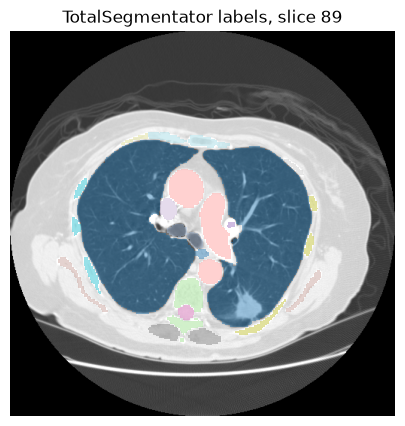

In [12]:
# C1. Run TotalSegmentator (skipped if a result already exists) and overlay a few structures
from totalsegmentator.python_api import totalsegmentator
from totalsegmentator.map_to_binary import class_map

out = 'data/work/ts/total.nii.gz'
if not os.path.exists(out):
    t = time.perf_counter()
    totalsegmentator(ct_dir, out, ml=True, device='gpu' if DEVICE == 'cuda' else 'cpu', fast=DEVICE != 'cuda')
    print(f'TotalSegmentator took {time.perf_counter() - t:.0f} s')
labels = sitk.GetArrayFromImage(sitk.Resample(sitk.ReadImage(out), ct, sitk.Transform(), sitk.sitkNearestNeighbor, 0))
names = class_map['total']
voxel_ml = sx * sy * sz / 1000
for part in ['lung_lower_lobe_left', 'heart', 'aorta', 'liver']:
    i = [k for k, v in names.items() if v == part][0]
    print(f'{part:22s} {np.sum(labels == i) * voxel_ml:8.1f} ml')

plt.figure(figsize=(5, 5))
plt.imshow(window(arr[z], -600, 1500), cmap='gray')
plt.imshow(np.ma.masked_equal(labels[z], 0), cmap='tab20', alpha=0.45, interpolation='nearest')
plt.axis('off'); plt.title('TotalSegmentator labels, slice 89'); plt.show()

In [13]:
# C2. Check against the radiologists: does any label mark the nodule? Where does MedSAM agree?
seg_files = sorted(glob.glob(os.path.join(LIDC, 'SEG-*', '*.dcm')))
readers = []
for f in seg_files:
    s = pydicom.dcmread(f)
    m = np.zeros(arr.shape, bool)
    for fr, plane in zip(np.atleast_3d(s.pixel_array.transpose(1, 2, 0)).transpose(2, 0, 1), s.PerFrameFunctionalGroupsSequence):
        kz = int(round((float(plane.PlanePositionSequence[0].ImagePositionPatient[2]) - ct.GetOrigin()[2]) / sz))
        m[kz] |= fr.astype(bool)
    readers.append(m)
nodule = np.any(readers, axis=0)
lung_ids = [k for k, v in names.items() if v.startswith('lung_')]
print(f'Nodule voxels inside the TotalSegmentator lung label: {np.isin(labels[nodule], lung_ids).mean():.1%}')
print('-> the lung outline swallows the tumour; this model outlines anatomy, not disease')

def dice(a, b): return float(2 * (a & b).sum() / (a.sum() + b.sum()))
print('Radiologist vs radiologist (3D Dice):', [round(dice(readers[0], r), 2) for r in readers[1:]])

Nodule voxels inside the TotalSegmentator lung label: 99.9%
-> the lung outline swallows the tumour; this model outlines anatomy, not disease


Radiologist vs radiologist (3D Dice): [0.84, 0.87, 0.89]


In [14]:
# C3. MedSAM: a box around the nodule on slice 89 -> an outline, compared with each radiologist
from transformers import SamModel, SamProcessor
ys, xs = np.nonzero(nodule[z])
box = [int(xs.min()) - 5, int(ys.min()) - 5, int(xs.max()) + 5, int(ys.max()) + 5]
rgb = np.repeat((window(arr[z], 40, 400) * 255).astype(np.uint8)[..., None], 3, axis=2)
proc = SamProcessor.from_pretrained('wanglab/medsam-vit-base')
sam = SamModel.from_pretrained('wanglab/medsam-vit-base').to(DEVICE).eval()
with torch.no_grad():
    inp = proc(rgb, input_boxes=[[box]], return_tensors='pt').to(DEVICE)
    out_ = sam(**inp, multimask_output=False)
mask = proc.image_processor.post_process_masks(out_.pred_masks.sigmoid().cpu(), inp['original_sizes'].cpu(),
                                               inp['reshaped_input_sizes'].cpu(), binarize=False)[0][0, 0].numpy() > 0.5
print('MedSAM vs each radiologist (Dice on this slice):', [round(dice(mask, r[z]), 2) for r in readers])

Loading weights:   0%|          | 0/315 [00:00<?, ?it/s]

MedSAM vs each radiologist (Dice on this slice): [0.75, 0.76, 0.76, 0.77]


## Interpreting what you saw

* **Cosine scores** rank options for one image. They are not probabilities, and not diagnoses. Small gaps mean the model is unsure.
* **Softmax "probabilities"** from CLIP-style models are not calibrated; do not report them as confidence.
* **Segmentation** is only as good as its purpose: TotalSegmentator outlines anatomy and silently includes the tumour inside "lung".
* **Agreement** between experts is itself imperfect (Dice about 0.84–0.90 here), so a model's Dice must be judged against that.
* **Preparation** choices (window, resize, which series) change results. Write them down.

## Save this run's numbers for the slides

In [15]:
# Record what this run produced, so the slides can show where their numbers came from
os.makedirs('../data/runs', exist_ok=True)
json.dump({'device': torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU',
           'biomedclip_seconds_per_image': timings,
           'patient_xray_ranking': {candidates[i]: round(float(cosine[i]), 4) for i in np.argsort(-cosine)},
           'softmax_top2': [round(float(p[top2[0]]), 3), round(float(p[top2[1]]), 3)],
           'medsam_dice_vs_readers': [round(float(dice(mask, r[z])), 3) for r in readers],
           'run_date': time.strftime('%Y-%m-%d')},
          open('../data/runs/notebook.json', 'w'), indent=1)
print('saved ../data/runs/notebook.json')

saved ../data/runs/notebook.json
